In [24]:
import emcee
import corner
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle
from uncertainties import ufloat
from uncertainties.umath import *
from uncertainties import unumpy as unp
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM
cosmo=FlatLambdaCDM(70, 0.3)
from statistics_functions import chi_squared
from load_data_and_var import generate_nfws_from_combined_dataset_werr

In [43]:
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
    combined_data = pickle.load(f)
low_z_data = combined_data[combined_data['z_y'] < 0.2][combined_data['Sub-Cat']=='REFLEX'][['OName','AName', 'L500', 'z_y']].rename(columns={'AName': 'Name'}).dropna()

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_83489/3620387234.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = combined_data[combined_data['z_y'] < 0.2][combined_data['Sub-Cat']=='REFLEX'][['OName','AName', 'L500', 'z_y']].rename(columns={'AName': 'Name'}).dropna()


In [45]:
low_z_data

,OName,Name,L500,z_y
2,RXCJ0003.8+0203,A2700,0.846881,0.0924
3,RXCJ0006.0-3443,A2721,1.809494,0.1147
6,RXCJ0011.3-2851,A2734,1.086002,0.0620
9,RXCJ0013.6-1930,A0013,1.236332,0.0940
10,RXCJ0014.3-6604,A2746,2.827248,0.1599
...,...,...,...,...
541,RXCJ2344.2-0422,,1.852614,0.0786
543,RXCJ2347.7-2808,A4038,1.029501,0.0300
547,RXCJ2354.2-1024,A2670,1.336537,0.0765
549,RXCJ2357.0-3445,A4059,1.629622,0.0475


In [72]:
reflex_data = pd.read_csv('data/reflex70.txt', header=7, sep='|', skiprows=[range(6), 8],on_bad_lines='warn', skipfooter=1, skipinitialspace=True).rename(columns=lambda x: x.strip())
#data = data.apply(lambda x: x.str.strip() if x.dtype == 'object' else x)
#data['Name'].values.strip()
reflex_data = reflex_data.apply(lambda x: x.str.strip() if x.dtype == 'object' else x)[['RXC', 'Flux', 'e_Flux', 'ObsLum', 'LumCor', 'z']].dropna()

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_83489/2434024660.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.
  reflex_data = pd.read_csv('data/reflex70.txt', header=7, sep='|', skiprows=[range(6), 8],on_bad_lines='warn', skipfooter=1, skipinitialspace=True).rename(columns=lambda x: x.strip())


In [73]:
reflex_data.head()

,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.1-0605,4.497,12.4,6.395,6.876,0.2320
1,RXCJ0003.2-3555,7.537,17.8,0.421,0.478,0.0490
2,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
3,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
4,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620


In [74]:
comb = pd.merge(low_z_data, reflex_data, left_on='OName', right_on='RXC', how='inner', sort=True)

In [75]:
comb

,OName,Name,L500,z_y,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.8+0203,A2700,0.846881,0.0924,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
1,RXCJ0006.0-3443,A2721,1.809494,0.1147,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
2,RXCJ0011.3-2851,A2734,1.086002,0.0620,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620
3,RXCJ0013.6-1930,A0013,1.236332,0.0940,RXCJ0013.6-1930,6.071,11.3,1.285,1.353,0.0940
4,RXCJ0014.3-6604,A2746,2.827248,0.1599,RXCJ0014.3-6604,4.485,13.8,2.907,3.160,0.1599
...,...,...,...,...,...,...,...,...,...,...
168,RXCJ2344.2-0422,,1.852614,0.0786,RXCJ2344.2-0422,12.638,7.4,1.855,2.061,0.0786
169,RXCJ2347.7-2808,A4038,1.029501,0.0300,RXCJ2347.7-2808,49.578,3.8,1.014,1.127,0.0300
170,RXCJ2354.2-1024,A2670,1.336537,0.0765,RXCJ2354.2-1024,9.622,12.1,1.337,1.469,0.0765
171,RXCJ2357.0-3445,A4059,1.629622,0.0475,RXCJ2357.0-3445,32.663,5.5,1.698,1.787,0.0475


In [61]:
ONames = (comb['OName'].tolist())

In [64]:
# calculate flux with variance in watts
flux_arr=comb['Flux'].to_numpy()*1e-15 # to get in watts
eflux_arr=comb['e_Flux'].to_numpy()
flux_var=np.array([ufloat(flux_arr[i],eflux_arr[i]*flux_arr[i]/100) for i in range(len(flux_arr))])

In [78]:
# Calculate Lobs from flux with variance

d_L = cosmo.comoving_distance(comb['z_y']).to(u.m).value #(return meters)
#originally in units u.W*1e-15/u.m**2 * Mpc**2
Lobs_calc=(flux_var*4*np.pi*d_L**2) * 1e-37 

#Lobs_calc #now in units of 1e37 W
Lobs_err = [L.std_dev for L in Lobs_calc]
#Lobs_err
Lobs_calc

array([0.745922576900713+/-0.14023344445733404,
       1.5962288643873468+/-0.21708712555667914,
       0.9850814005299323+/-0.0886573260476939,
       1.1271051139128871+/-0.12736287787215625,
       2.333867767423409+/-0.3220737519044305,
       2.4135326772236376+/-0.2920374539440601,
       0.45618706030144873+/-0.04425014484924054,
       1.8425238329482687+/-0.3150715754341539,
       1.2636774736720755+/-0.16806910399838607,
       1.2026954179964795+/-0.09501293802172188,
       4.890977692536981+/-0.1565112861611834,
       2.3879872138694673+/-0.2340227469592078,
       1.4123668858975584+/-0.0748554449525706,
       1.3174099397720227+/-0.08826646596472552,
       0.4175108555327666+/-0.04091606384221112,
       0.17222891932443235+/-0.01377831354595459,
       0.45404892283675474+/-0.042226549823818196,
       0.7175482809428992+/-0.05668631419448903,
       1.7091148865220904+/-0.27345838184353455,
       3.1578969342457186+/-0.42315818918892634,
       1.4289856888365742+

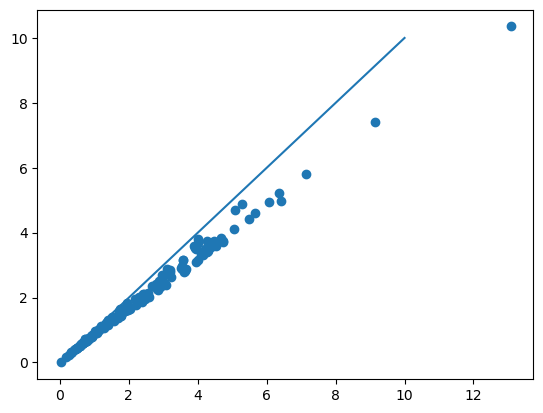

In [79]:
plt.scatter(comb['ObsLum'], [L.nominal_value for L in Lobs_calc])
plt.plot([0,10], [0,10])

In [80]:
# MCMC: L_o=(L_c - b)/m 
# change to L_o=(L500-b)/m
L_obs_data = comb['ObsLum']
L_obs_var=[L.std_dev for L in Lobs_calc]
#L_cor=comb['LumCor']
L500=comb['L500']

Text(0, 0.5, 'L500')

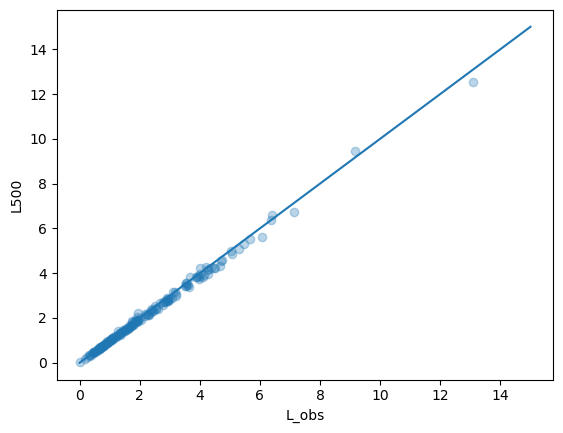

In [82]:
plt.scatter(L_obs_data, L500, alpha=0.3)
plt.plot(np.linspace(0,15), np.linspace(0,15))
plt.xlabel('L_obs')
plt.ylabel('L500')

In [83]:
def log_lik(p0, L_c, obs, var):
    m=p0[0]
    if np.abs(m)<0.00001:
        return -np.inf
    b=p0[1]
    if np.abs(m)>10 or np.abs(b)>10:
        return -np.inf
    pred=(L_c-b)/m
    return -1*chi_squared(pred, obs, var)/2

In [85]:
p0=[1, 0]
log_lik(p0, L500, L_obs_data, np.array(L_obs_var))

-23.439121240851986

In [86]:
ndim=2
nwalkers = 32
guess=(1, 0)
p0 = guess+np.random.normal(scale=0.1, size=(nwalkers, ndim))
p0

array([[ 1.02007026, -0.0585628 ],
       [ 1.05910824, -0.14424085],
       [ 1.0317431 ,  0.04440829],
       [ 0.93765148, -0.26762834],
       [ 0.958862  ,  0.06090533],
       [ 1.06900546,  0.02942311],
       [ 1.14119586, -0.06538478],
       [ 1.1545561 , -0.01393333],
       [ 1.04657785,  0.12988137],
       [ 0.942009  , -0.00779856],
       [ 0.90009229,  0.04740636],
       [ 1.07092126, -0.09342767],
       [ 1.02576936, -0.09392942],
       [ 1.02846363,  0.11337956],
       [ 1.04924025, -0.03143122],
       [ 0.86338749, -0.12844961],
       [ 0.93114758, -0.07093385],
       [ 1.16839471, -0.07755022],
       [ 1.14999077,  0.0121968 ],
       [ 1.08543879,  0.11962898],
       [ 1.13074722, -0.09735466],
       [ 1.0825406 , -0.05917657],
       [ 0.93782252,  0.03238927],
       [ 1.00567219, -0.07091397],
       [ 0.9402358 ,  0.07385866],
       [ 0.98773489,  0.04913702],
       [ 1.13051964, -0.00890428],
       [ 1.10312267, -0.04292069],
       [ 1.01311561,

In [87]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_lik, args=[L500, L_obs_data, np.array(L_obs_var)])

In [88]:
state = sampler.run_mcmc(p0, 100, progress=True)
sampler.reset()

100%|████████████████████████████████████████| 100/100 [00:00<00:00, 138.80it/s]


In [89]:
sampler.run_mcmc(state, 5000, progress=True)

100%|██████████████████████████████████████| 5000/5000 [00:34<00:00, 142.96it/s]


State([[ 0.97068963  0.00614981]
 [ 0.98498832 -0.01039627]
 [ 0.98075295  0.00656581]
 [ 0.98421016  0.00125746]
 [ 0.97459085  0.00118845]
 [ 0.97874858 -0.00408067]
 [ 0.97446896  0.00436298]
 [ 0.96344669  0.01677152]
 [ 0.97705341  0.00234503]
 [ 0.97326387  0.00436658]
 [ 0.97270567  0.01290578]
 [ 0.98848046  0.00162523]
 [ 0.96912431  0.00914621]
 [ 0.98103849  0.00382066]
 [ 0.97538044  0.00181392]
 [ 0.96023786  0.01247329]
 [ 0.97393123  0.00559742]
 [ 0.97534702  0.0052293 ]
 [ 0.97266104  0.00852534]
 [ 0.98071865 -0.00607339]
 [ 0.96196024  0.02032119]
 [ 0.97874504  0.00169576]
 [ 0.96368784  0.01553453]
 [ 0.96726191  0.00571622]
 [ 0.96691199  0.01196579]
 [ 0.98183374 -0.00202032]
 [ 0.9779869   0.00632111]
 [ 0.97068704  0.00215621]
 [ 0.96838242  0.00791913]
 [ 0.96855381  0.00921792]
 [ 0.96901967  0.00685468]
 [ 0.96648458  0.01141502]], log_prob=[-15.05294386 -18.64704096 -15.83265502 -15.91764745 -15.1977932
 -16.25074365 -14.85602454 -17.45375533 -14.95442684 -

In [90]:
flat_samples = sampler.get_chain(flat=True)
print(flat_samples.shape)

(160000, 2)


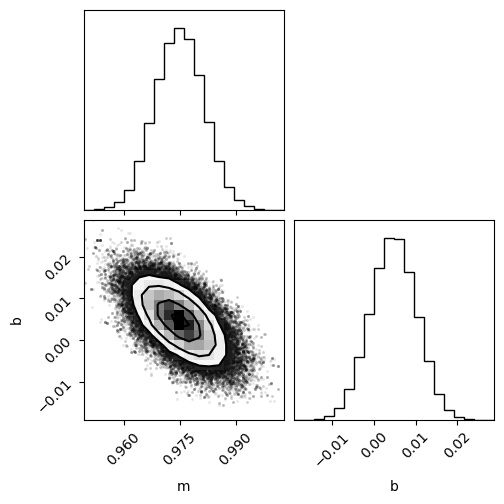

In [91]:
fig = corner.corner(flat_samples, labels=['m', 'b']) 

In [92]:
tau = sampler.get_autocorr_time()
print(tau)

[29.70804334 31.67100762]


In [93]:
np.median(flat_samples[:,0]), np.median(flat_samples[:,1])

(0.9748792141626473, 0.004704619706240882)

In [94]:
m_err=np.var(flat_samples[:,0]) # var=mean((p-pmean)**2)
m_err

4.21379857982293e-05

In [95]:
b_err=np.var(flat_samples[:,1])
b_err

3.0339356288856e-05

In [96]:
m_uf=ufloat(np.median(flat_samples[:,0]), np.var(flat_samples[:,0]))
b_uf=ufloat(np.median(flat_samples[:,1]), np.var(flat_samples[:,1]))

m_uf, b_uf # uncertainty too small??

(0.9748792141626473+/-4.21379857982293e-05,
 0.004704619706240882+/-3.0339356288856e-05)

In [97]:
# get L500 based on this relationship that we found
L_obs_uf=unp.uarray(comb['ObsLum'], [L.std_dev for L in Lobs_calc])

L500_pred=m_uf*L_obs_uf+b_uf

In [98]:
L500_uf=unp.uarray(comb['L500'], [L.std_dev for L in L500_pred])
L500_uf

array([0.846881+/-0.1367106782457075, 1.809494+/-0.21163374329028592,
       1.086002+/-0.08643020185380633, 1.236332+/-0.12416343780695728,
       2.827248+/-0.31398303151950574, 2.872451+/-0.2847012716121661,
       0.49467+/-0.043138562128386584, 2.164603+/-0.30715674595625836,
       1.404549+/-0.1638470908856745, 1.253723+/-0.0926261610507552,
       5.100085+/-0.1525797656906765, 2.734146+/-0.22814394391691856,
       1.437223+/-0.0729750512139522, 1.460216+/-0.08604916968964585,
       0.491051+/-0.03988823633141873, 0.181484+/-0.013432227863703348,
       0.467516+/-0.041165802025106744, 0.763259+/-0.05526232748800824,
       2.010759+/-0.26658890751185765, 4.237381+/-0.4125281586647469,
       1.768408+/-0.2493628448242539, 0.561478+/-0.06529545963790753,
       0.669697+/-0.0846151267509943, 0.334315+/-0.14423960684426362,
       1.027456+/-0.08368487084099077, 3.815928+/-0.1335505926960308,
       0.593611+/-0.05294124312461238, 1.467361+/-0.0960058368690142,
       3.817746

In [99]:
# grab predicted L errs
L_errs = [L.std_dev for L in L500_pred]
len(L_errs)

173

In [100]:
dict_name_err = dict(zip(comb['OName'], L_errs))

In [101]:
dict_name_err['RXCJ0011.3-2851']

0.08643020185380633

In [102]:
import pickle
with open('data/REFLEX_lowz_errs.p', 'wb') as fp:
    pickle.dump(dict_name_err, fp)

In [103]:
dict_name_err

{'RXCJ0003.8+0203': 0.1367106782457075,
 'RXCJ0006.0-3443': 0.21163374329028592,
 'RXCJ0011.3-2851': 0.08643020185380633,
 'RXCJ0013.6-1930': 0.12416343780695728,
 'RXCJ0014.3-6604': 0.31398303151950574,
 'RXCJ0020.7-2542': 0.2847012716121661,
 'RXCJ0025.5-3302': 0.043138562128386584,
 'RXCJ0027.3-5015': 0.30715674595625836,
 'RXCJ0028.6-2338': 0.1638470908856745,
 'RXCJ0034.6-0208': 0.0926261610507552,
 'RXCJ0041.8-0918': 0.1525797656906765,
 'RXCJ0042.1-2832': 0.22814394391691856,
 'RXCJ0056.3-0112': 0.0729750512139522,
 'RXCJ0102.7-2152': 0.08604916968964585,
 'RXCJ0108.8-1524': 0.03988823633141873,
 'RXCJ0110.0-4555': 0.013432227863703348,
 'RXCJ0115.2+0019': 0.041165802025106744,
 'RXCJ0120.9-1351': 0.05526232748800824,
 'RXCJ0145.0-5300': 0.26658890751185765,
 'RXCJ0145.2-6033': 0.4125281586647469,
 'RXCJ0206.4-1453': 0.2493628448242539,
 'RXCJ0229.3-3332': 0.06529545963790753,
 'RXCJ0236.6-1923': 0.0846151267509943,
 'RXCJ0311.4-2653': 0.14423960684426362,
 'RXCJ0314.3-4525': 0.

In [105]:
comb['OName']

0      RXCJ0003.8+0203
1      RXCJ0006.0-3443
2      RXCJ0011.3-2851
3      RXCJ0013.6-1930
4      RXCJ0014.3-6604
            ...       
168    RXCJ2344.2-0422
169    RXCJ2347.7-2808
170    RXCJ2354.2-1024
171    RXCJ2357.0-3445
172    RXCJ2359.3-6042
Name: OName, Length: 173, dtype: object